   # Lab 2 – OD Matrices analytics 
   ## Focus on Torino, applying lab1 filters

Setup functions and datasets

In [32]:
pip install pymongo

Note: you may need to restart the kernel to use updated packages.


In [33]:
import pymongo as pm
from pprint import pprint
import datetime
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Carsharing data

In [34]:
client = pm.MongoClient(
    'bigdatadb.polito.it',
    ssl=True,
    authSource='carsharing',
    username='ictts',
    password='Ict4SM22!',
    tlsAllowInvalidCertificates=True
)

In [35]:
db = client['carsharing']
pb_coll = db['ictts_PermanentBookings']
pb_coll_enjoy= db['ictts_enjoy_PermanentBookings']

In [36]:
list(pb_coll.find().limit(1))
list(pb_coll_enjoy.find().limit(1))

[{'_id': ObjectId('5a3bb23920c3dd4716519e40'),
  'final_fuel': 56,
  'init_fuel': 57,
  'plate': 'EZ807DD',
  'car_category_id': 8,
  'driving': {'distance': 3948, 'duration': 545},
  'onClick_disabled': False,
  'init_loc': {'coordinates': [7.7029123, 45.07156], 'type': 'Point'},
  'walking': {'distance': 3776, 'duration': 2849},
  'virtual_rental_id': 361384,
  'car_category_type_id': 1,
  'carModelData': [99, 100, 141],
  'virtual_rental_type_id': 2,
  'final_address': 'Via Arcangelo Corelli, 41, 10154 Torino TO',
  'init_address': 'Corso Carlo Luigi Farini, 20, 10153 Torino TO',
  'final_time': 1509491472,
  'public_transport': {'distance': 4034,
   'duration': 1377,
   'arrival_time': 1509493666,
   'arrival_date': datetime.datetime(2017, 11, 1, 0, 47, 46)},
  'init_date': datetime.datetime(2017, 10, 31, 23, 58, 50),
  'final_date': datetime.datetime(2017, 11, 1, 0, 11, 12),
  'city': 'Torino',
  'vendor': 'enjoy',
  'init_time': 1509490730,
  'final_loc': {'coordinates': [7.70973

In [37]:
results=pb_coll_enjoy.aggregate([
    {'$project': {
        'hour':{'$hour':'$init_date'},
        'day':{'$dayOfWeek':'$init_date'},
        'init_loc':1,
        'final_loc':1
    }},
    {'$match':{
        'hour': {'$gte':0,'$lt':12},
        'day':{'$gte':2,'$lt':7}
    }} ,
    {'$count':'tot'}
])

In [38]:
res = list(results)
print(res[0]['tot'])

23148


IMQ

UNIPOL

# Functions for task 1

### We used the narrowest interval on a log scale that contains a fraction Q = 90% of the bookings. We will use the same method for this lab.

In [39]:
import json, os, time
from matplotlib.path import Path

os.makedirs('out', exist_ok=True)
Q = 0.90

I'm using the same code of lab1 guys

In [40]:
def best_zone(x, q=Q, log=True, threshold=False, min_duration=1.0):
    x = np.sort(np.asarray(x, dtype=float))
    if threshold:
        x = x[x >= min_duration]
    else:
        x = x[x >= 0]
    n = len(x)
    if n == 0:
        return np.nan, np.nan
    k = int(np.ceil(q * n))
    t = np.log(x) if log else x
    widths = t[k - 1:] - t[: n - k + 1]
    i = np.argmin(widths)
    return x[i], x[i + k - 1]


def keep_best_zone(df, q=Q, col='duration_min', log=True, threshold=False):
    a, b = best_zone(df[col].values, q, log, threshold)
    return df[df[col].between(a, b)].copy(), (a, b)


def load_bookings(coll):
    """
    All Torino bookings of a collection: start date, duration, origin and destination coordinates.
    I changed the load_wtime of lab1
    """
    docs = coll.aggregate([
        {'$match': {'city': 'Torino',
                    'driving.distance': {'$gt': 0}}},   #To use the same filter
        {'$project': {
            '_id': 0,
            'init_date': 1,
            'duration': {'$subtract': ['$final_time', '$init_time']},
            'orig_lon': {'$arrayElemAt': ['$init_loc.coordinates', 0]},
            'orig_lat': {'$arrayElemAt': ['$init_loc.coordinates', 1]},
            'dest_lon': {'$arrayElemAt': ['$final_loc.coordinates', 0]},
            'dest_lat': {'$arrayElemAt': ['$final_loc.coordinates', 1]},
        }},
    ], allowDiskUse=True)
    df = pd.DataFrame(list(docs))
    df['duration_min'] = df['duration'] / 60
    return df



def plot_cdf_filtered(df, df_f, zone, title, ax):
    """Lab 1 plot"""
    for d, style, lab in [(df, "-", "not filtered"), (df_f, "--", "filtered")]:
        x = np.sort(d["duration_min"].to_numpy())
        x = x[x > 0]
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), style,
                label=f"{lab} (median {np.median(x):.1f} min)")
    ax.axvspan(*zone, color="grey", alpha=0.15)
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Duration (min, log scale)")
    ax.set_ylabel("CDF")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)

In [41]:
for name, coll in [('car2go', pb_coll), ('enjoy', pb_coll_enjoy)]:
    tot = coll.count_documents({'city': 'Torino'})
    moved = coll.count_documents({'city': 'Torino', 'driving.distance': {'$gt': 0}})
    print(f'{name}: {tot - moved} of {tot} bookings removed (car not moved)')

car2go: 82477 of 121667 bookings removed (car not moved)
enjoy: 61447 of 97173 bookings removed (car not moved)


Zones of Torino 

In [42]:
FILE_ORDER = [f'Q{i:03d}' for i in range(1, 20)] + ['Q021', 'Q022', 'Q020', 'Q023']
"""
I checked the IMQ files to understand how to devide the zones. I don't know if its completely right but I changed the order to follow 
one of the files list.
"""
def load_zones(path, names_path='data/IMQ/IMQData/tab_zone_IMQ.csv'):
    """Read the 23 zones of Torino.
    Returns {zone code: GeoJSON geometry}, the sorted list of codes and {zone code: zone name}
    (names from tab_zone_IMQ.csv of the IMQ data)."""
    with open(path) as f:
        fc = json.load(f)
    zones = {code: feature['geometry'] for code, feature in zip(FILE_ORDER, fc['features'])}
    table = pd.read_csv(names_path, encoding='latin-1', dtype=str).set_index('COD_ZONA')['nome_zona']
    names = {code: table[code].replace('TORINO - ', '').title() for code in zones}
    return zones, sorted(zones), names


def point_zone(lon, lat, zones):
    """Zone code of each point (lon, lat); None if the point is outside all zones """
    pts = np.column_stack([np.asarray(lon, float), np.asarray(lat, float)])
    out = np.full(len(pts), None, dtype=object)
    for code in sorted(zones):
        geom = zones[code]
        polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
        inside = np.zeros(len(pts), dtype=bool)
        for poly in polys:
            m = Path(poly[0]).contains_points(pts)
            for hole in poly[1:]:
                m &= ~Path(hole).contains_points(pts)
            inside |= m
        out[inside & pd.isna(out)] = code
    return out


def assign_zones(df, zones):
    """Adds the columns orig and dest (zone codes) and keeps only bookings inside the Torino zones."""
    df = df.copy()
    df['orig'] = point_zone(df.orig_lon, df.orig_lat, zones)
    df['dest'] = point_zone(df.dest_lon, df.dest_lat, zones)
    inside = df.dropna(subset=['orig', 'dest'])
    print(f'{len(inside)}/{len(df)} bookings start and end inside the Torino zones ({len(inside) / len(df):.1%})')
    return inside

Time columns to compare diff periods

In [43]:
def add_time_columns(df):
    """Adds date, hour, day of week and week number
    counted from the first full week"""
    df = df.copy()
    d = pd.to_datetime(df['init_date'])
    df['date'] = d.dt.strftime('%Y-%m-%d')
    df['hour'] = d.dt.hour
    df['dow'] = d.dt.dayofweek
    first = d.min().normalize()
    monday1 = first + pd.Timedelta(days=(7 - first.weekday()) % 7 or 7)
    df['week'] = (d.dt.normalize() - monday1).dt.days // 7 + 1
    return df


def select_period(df, days='all', hours=None, weeks=None, holidays=()):
    """Bookings in a given period.
    days     : 'all', 'weekdays' Mon-Fri, 'weekend' Sat-Sun
    hours    : (start, end). if start > end it goes over midnight
    if it starts at 22 and arrive at 4 in the morning, it will be (22, 4) bravo scrivi ste cose che poi te le dimentichi
    weeks    : list of week numbers
    holidays : dates 'YYYY-MM-DD' falling on weekdays, removed from 'weekdays'"""
    mask = pd.Series(True, index=df.index)
    if days == 'weekdays':
        mask &= (df.dow < 5) & ~df.date.isin(holidays)
    elif days == 'weekend':
        mask &= df.dow >= 5
    if hours is not None:
        start, end = hours
        if start <= end:
            mask &= (df.hour >= start) & (df.hour < end)
        else:
            mask &= (df.hour >= start) | (df.hour < end)
    if weeks is not None:
        mask &= df.week.isin(weeks)
    return df[mask]

Pandas pivot OD matrices

In [44]:
def normalize(m):
    """Each element divided by the total: the sum of the matrix becomes 1"""
    total = m.values.sum()
    return m / total if total > 0 else m


def od_matrix(df, zones_list, norm=True):
    """OD matrix with a pandas pivot table, always 23 x 23 in the order of zones_list."""
    m = pd.pivot_table(df, index='orig', columns='dest', values='duration_min',
                       aggfunc='count', fill_value=0)#ricordalo che l'hai messa l'ozpione
    m = m.reindex(index=zones_list, columns=zones_list, fill_value=0)
    m.index.name, m.columns.name = 'orig', 'dest'
    return normalize(m) if norm else m

def conditional_od(m):
    """Row-normalized OD matrix: P(destination j | origin i)"""
    rows = m.sum(axis=1)
    return m.div(rows.replace(0, np.nan), axis=0).fillna(0)

Heatmaps

In [45]:
from matplotlib.colors import LogNorm, Normalize
from matplotlib.ticker import LogLocator, ScalarFormatter, NullFormatter

def zone_labels(codes):
    return [f'{c} {ZONE_NAMES.get(c, "")}' for c in codes]


def plot_heatmaps(mats, title='', fname=None, label='fraction of trips', log=True):
    """mats = {label: OD matrix}, side by side with the SAME colour scale.
    log=True: logarithmic colour scale, so that small flows are visible next to the very large ones
    (centre, diagonal). Cells with no trips are drawn in light grey."""
    vals = np.concatenate([m.values.ravel() for m in mats.values()])
    pos = vals[vals > 0]
    if log:
        norm = LogNorm(vmin=np.percentile(pos, 1), vmax=pos.max())
    else:
        norm = Normalize(vmin=0, vmax=np.percentile(vals, 99))
    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('#dddddd')                               # colour of the empty cells . Real question is: is it useful?
    n = len(mats)
    fig, axes = plt.subplots(1, n, figsize=(7.5 * n, 7), squeeze=False, constrained_layout=True)
    for ax, (name, m) in zip(axes[0], mats.items()):
        data = np.ma.masked_where(m.values <= 0, m.values) if log else m.values
        im = ax.imshow(data, cmap=cmap, norm=norm)
        ax.set_title(name, fontsize=12)
        ax.set_xticks(range(len(m.columns))); ax.set_xticklabels(zone_labels(m.columns), rotation=90, fontsize=7)
        ax.set_yticks(range(len(m.index))); ax.set_yticklabels(zone_labels(m.index), fontsize=7)
        ax.set_xlabel('destination zone'); ax.set_ylabel('origin zone')
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.7, label=label + (' (log scale)' if log else ''))
    fig.suptitle(title, fontsize=14)
    if fname: fig.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()


def plot_difference(A, B, title='', fname=None):
    """Heatmap of A - B: red = more trips in A, blue = more in B."""
    D = A - B
    lim = np.abs(D.values).max()
    plt.figure(figsize=(8, 7))
    plt.imshow(D.values, cmap='RdBu_r', vmin=-lim, vmax=lim)
    plt.colorbar(label='A − B')
    plt.xticks(range(len(D.columns)), zone_labels(D.columns), rotation=90, fontsize=7)
    plt.yticks(range(len(D.index)), zone_labels(D.index), fontsize=7)
    plt.xlabel('destination zone'); plt.ylabel('origin zone'); plt.title(title)
    if fname: plt.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()

Functions for task 1a – different periods

Ideas taken from Mathilde's notebook: the same four periods (day = 06:00–21:59), the marginal probabilities
of origin (`pO`, trip generation) and destination (`pD`, trip attraction) drawn on the map, and the
**total variation distance** to measure how different two OD matrices are. I keep having problems with the matrices, I'm trying to understand how to use them

In [46]:
DAY_HOURS = (6, 22)   #I have doubts about it, I just took Mathilde's ones! 7-20 maybe?                      
HOLIDAYS = ['2017-11-01', '2017-12-08']     

PERIODS = {
    'Weekdays':   dict(days='weekdays', holidays=HOLIDAYS),
    'Weekends':   dict(days='weekend'),
    'Daytime':    dict(hours=DAY_HOURS),
    'Night-time': dict(hours=DAY_HOURS[::-1]),
}


def od_by_period(trips_df, zones_list, periods=PERIODS):
    """One OD matrix per period: raw counts, normalized matrixand numbr of trips."""
    out = {}
    for name, kw in periods.items():
        sel = select_period(trips_df, **kw)
        out[name] = {'counts': od_matrix(sel, zones_list, norm=False),
                     'probability': od_matrix(sel, zones_list),
                     'n_trips': len(sel)}
        print(f'{name:11s}: {len(sel):7d} trips')
    return out


def tvd(A, B):
    """Total variation distance: share of trips that would have to change
    origin-destination pair to turn matrix A into matrix B. 0 = identical, 100 = no pair in common."""
    return 0.5 * np.abs(A.values - B.values).sum() * 100


def top_changes(A, B, label_a='A', label_b='B', n=10):
    """The n OD pairs whose share of trips changes the most between A and B (in percentage points)."""
    D = (A - B).stack()
    idx = D.abs().sort_values(ascending=False).index[:n]
    return pd.DataFrame({
        'origin': [f'{o} {ZONE_NAMES[o]}' for o, _ in idx],
        'destination': [f'{d} {ZONE_NAMES[d]}' for _, d in idx],
        f'{label_a} (%)': [A.loc[o, d] * 100 for o, d in idx],
        f'{label_b} (%)': [B.loc[o, d] * 100 for o, d in idx],
        'difference (p.p.)': [D[(o, d)] * 100 for o, d in idx],
    }).round(2)

#updated it for a map visualization, I think its fine
def plot_zone_maps(values, zones, title='', fname=None, label=''):
    """values = {panel title: Series indexed by zone code}. Each zone of Torino coloured by its value,
    all panels with the same colour scale."""
    vmax = max(v.max() for v in values.values())
    norm = plt.Normalize(0, vmax)
    cmap = plt.get_cmap('YlOrRd')
    fig, axes = plt.subplots(1, len(values), figsize=(4.5 * len(values), 5), squeeze=False, constrained_layout=True)
    for ax, (name, v) in zip(axes[0], values.items()):
        for code, geom in zones.items():
            polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
            biggest = max((np.array(p[0]) for p in polys), key=len)
            for poly in polys:
                ring = np.array(poly[0])
                ax.fill(ring[:, 0], ring[:, 1], color=cmap(norm(v.get(code, 0))), edgecolor='black', linewidth=0.5)
            ax.text(biggest[:, 0].mean(), biggest[:, 1].mean(), code[1:], ha='center', va='center', fontsize=6)
        ax.set_aspect(1 / np.cos(np.radians(45.07)))
        ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes[0].tolist(), shrink=0.7, label=label)
    fig.suptitle(title)
    if fname: fig.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()

In [47]:
bookings = {'car2go': load_bookings(pb_coll),
            'enjoy': load_bookings(pb_coll_enjoy)}

bookings_f, zones_f = {}, {}
for name, df in bookings.items():
    bookings_f[name], zones_f[name] = keep_best_zone(df)
    print(name, 'kept interval (min):', zones_f[name])

car2go kept interval (min): (np.float64(8.15), np.float64(42.18333333333333))
enjoy kept interval (min): (np.float64(11.216666666666667), np.float64(45.166666666666664))


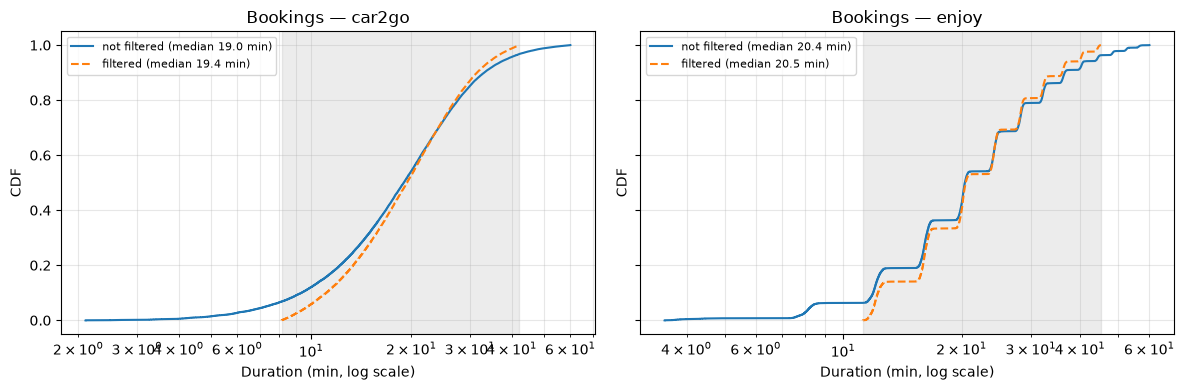

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ['car2go', 'enjoy']):
    plot_cdf_filtered(bookings[name], bookings_f[name], zones_f[name], f"Bookings — {name}", ax)
plt.tight_layout(); plt.show()

In [49]:
zones, ZONES, ZONE_NAMES = load_zones('data/IMQ/Zone/TorinoZonescol.geojson')
print(ZONE_NAMES)
trips = {name: add_time_columns(assign_zones(df, zones)) for name, df in bookings_f.items()}
#whatch the order!

{'Q001': 'Centro', 'Q002': 'S.Salvario', 'Q003': 'Crocetta', 'Q004': 'S.Paolo', 'Q005': 'Cenisia', 'Q006': 'S.Donato', 'Q007': 'Aurora', 'Q008': 'Vanchiglia', 'Q009': 'Nizza-Millefonti', 'Q010': 'Lingotto', 'Q011': 'S.Rita', 'Q012': 'Mirafiori Nord', 'Q013': 'Pozzo Strada', 'Q014': 'Parella', 'Q015': 'Vallette', 'Q016': 'Madonna Campagna', 'Q017': 'B.Ta Vittoria', 'Q018': 'B.Ra Milano', 'Q019': 'Falchera', 'Q021': 'Madonna Pilone', 'Q022': 'Cavoretto', 'Q020': 'Regio Parco', 'Q023': 'Mirafiori Sud'}
35036/35271 bookings start and end inside the Torino zones (99.3%)
31990/32154 bookings start and end inside the Torino zones (99.5%)


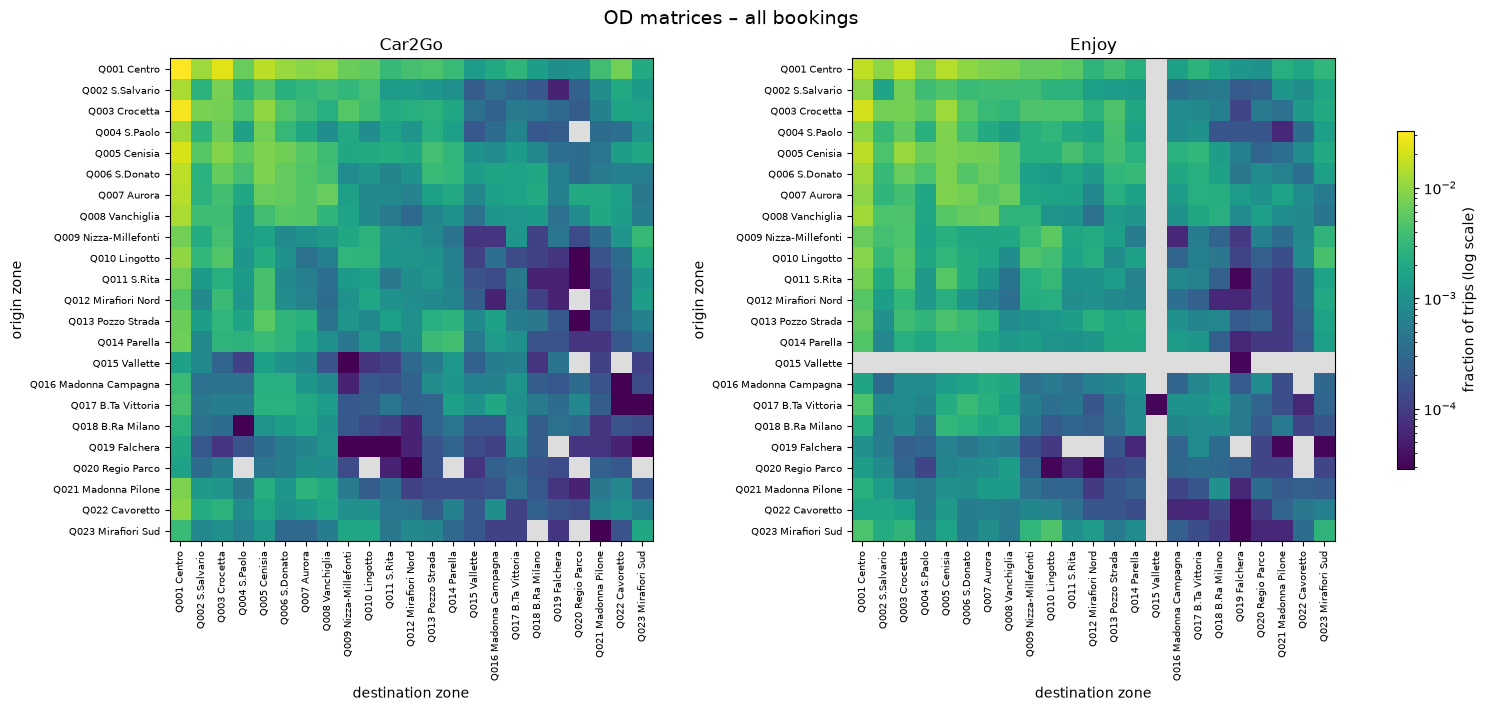

In [50]:
od_car2go = od_matrix(trips['car2go'], ZONES)
od_enjoy = od_matrix(trips['enjoy'], ZONES)
plot_heatmaps({'Car2Go': od_car2go, 'Enjoy': od_enjoy}, 'OD matrices – all bookings', 'task1_od')

# Task 1a – OD matrices on different periods

Weekdays vs weekends, daytime vs night-time, for Car2Go and Enjoy separately.
Every matrix is normalized, so periods with a different number of trips can be compared.

In [51]:
#preparation of the dict
od_periods = {}
for vendor in trips:
    print(vendor)
    od_periods[vendor] = od_by_period(trips[vendor], ZONES)
    print()

car2go
Weekdays   :   26158 trips
Weekends   :    8878 trips
Daytime    :   25484 trips
Night-time :    9552 trips

enjoy
Weekdays   :   23987 trips
Weekends   :    8003 trips
Daytime    :   21703 trips
Night-time :   10287 trips



### Heatmaps

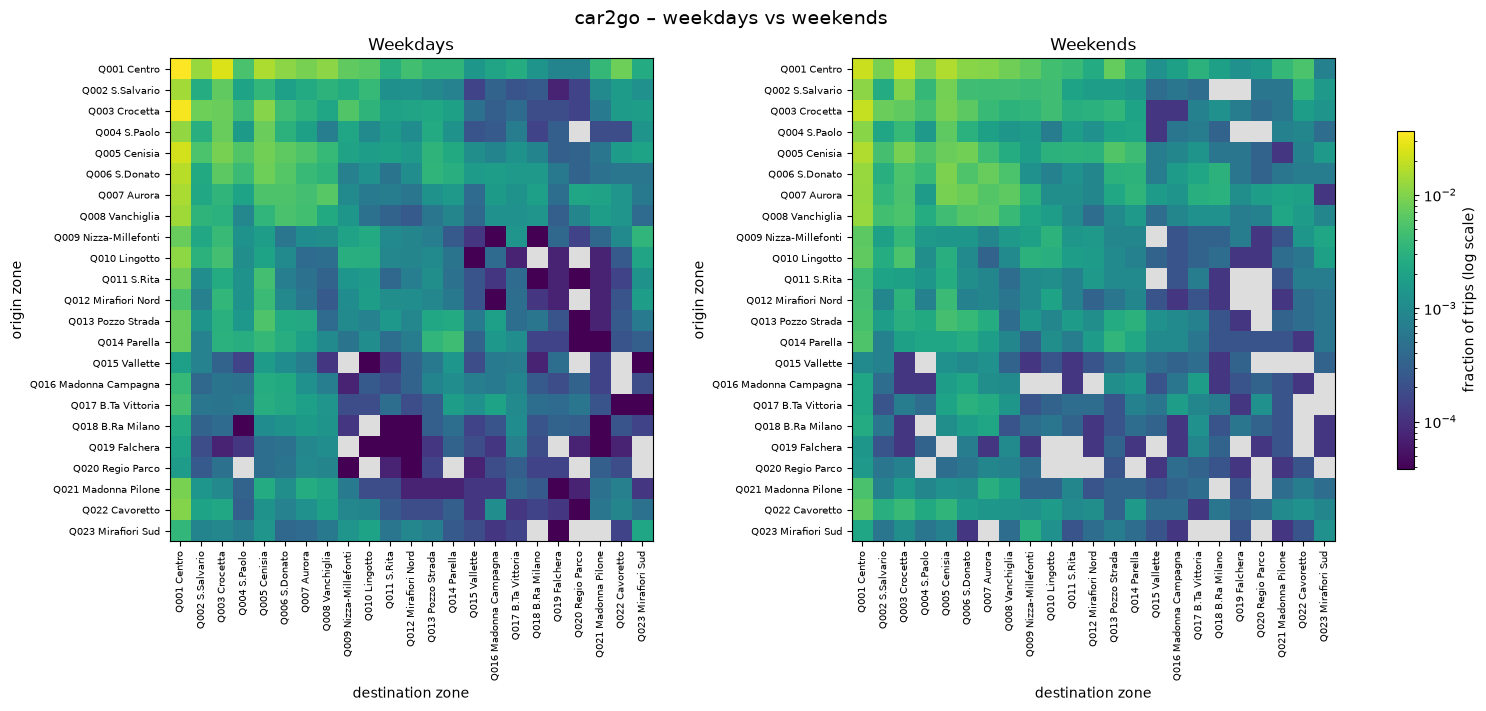

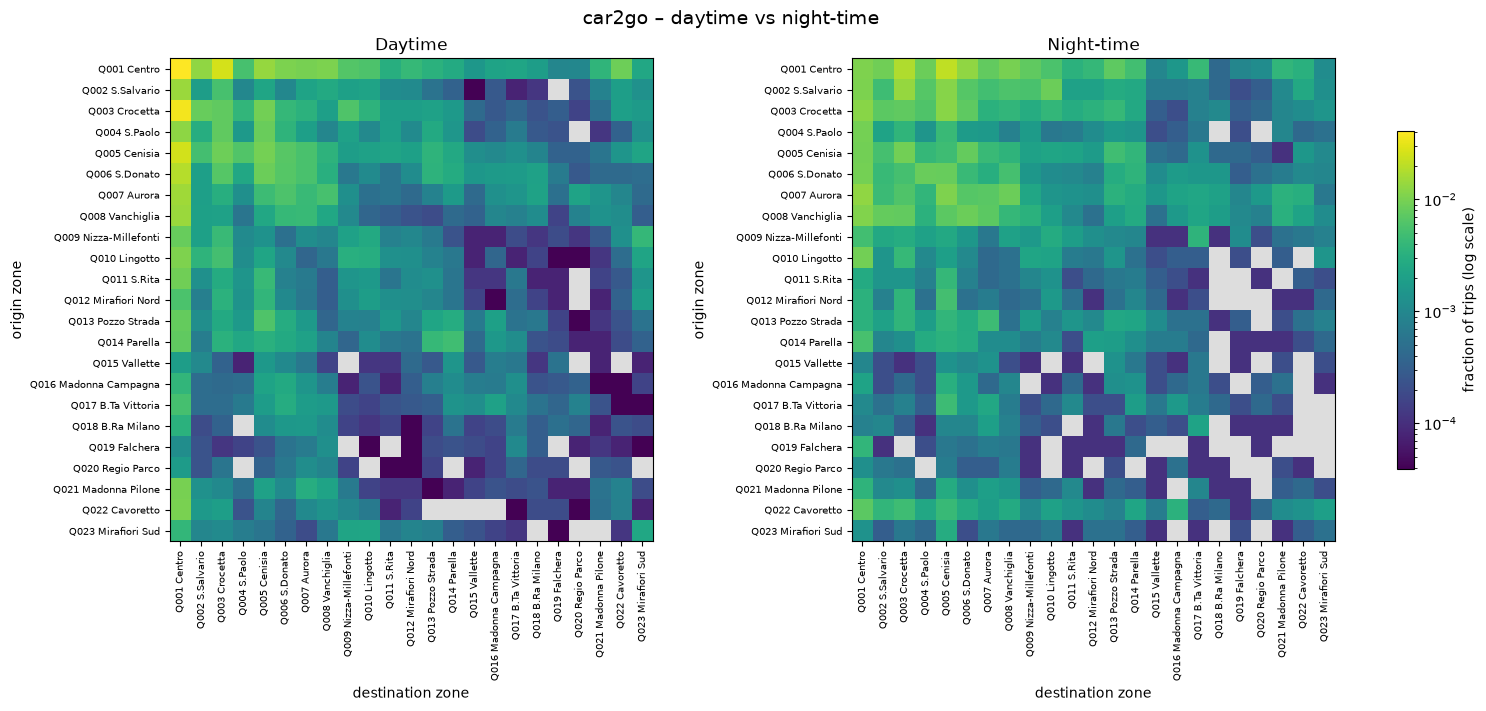

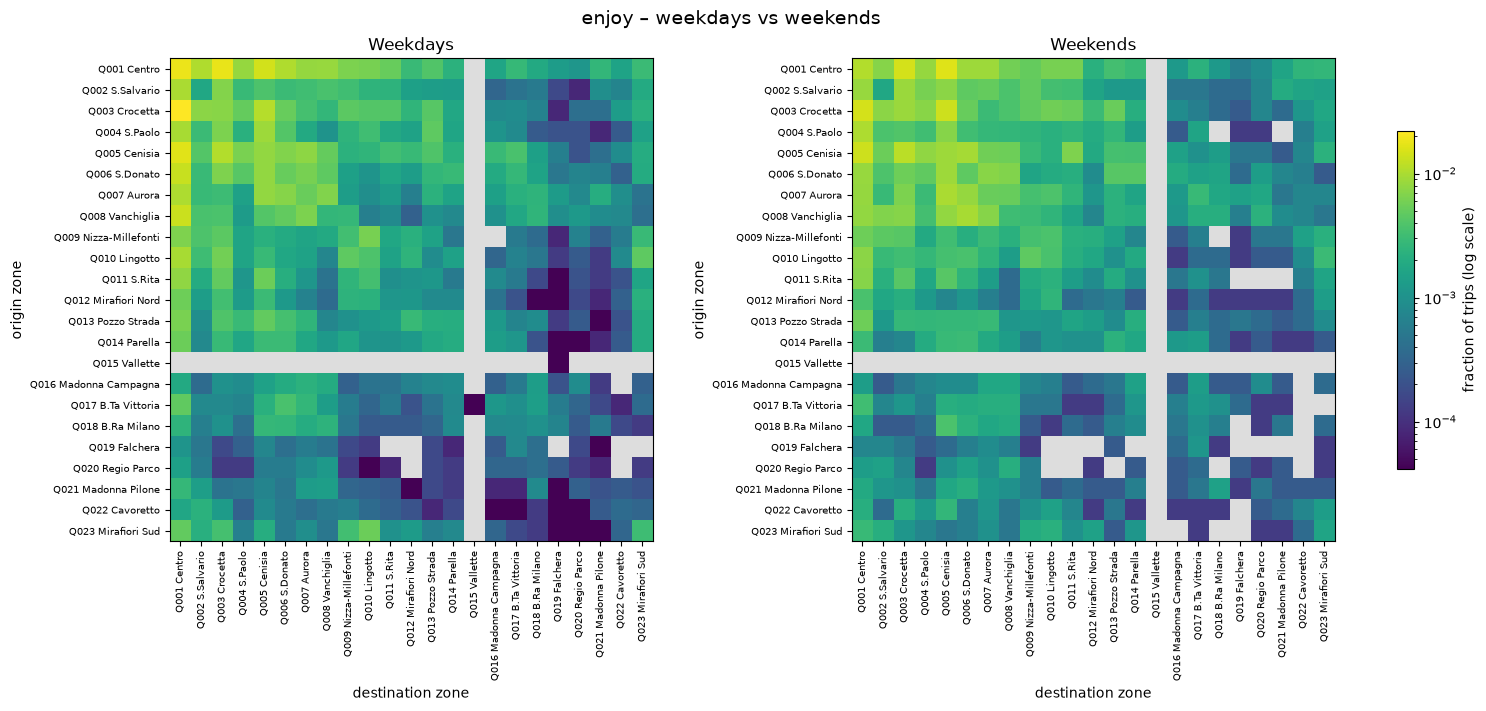

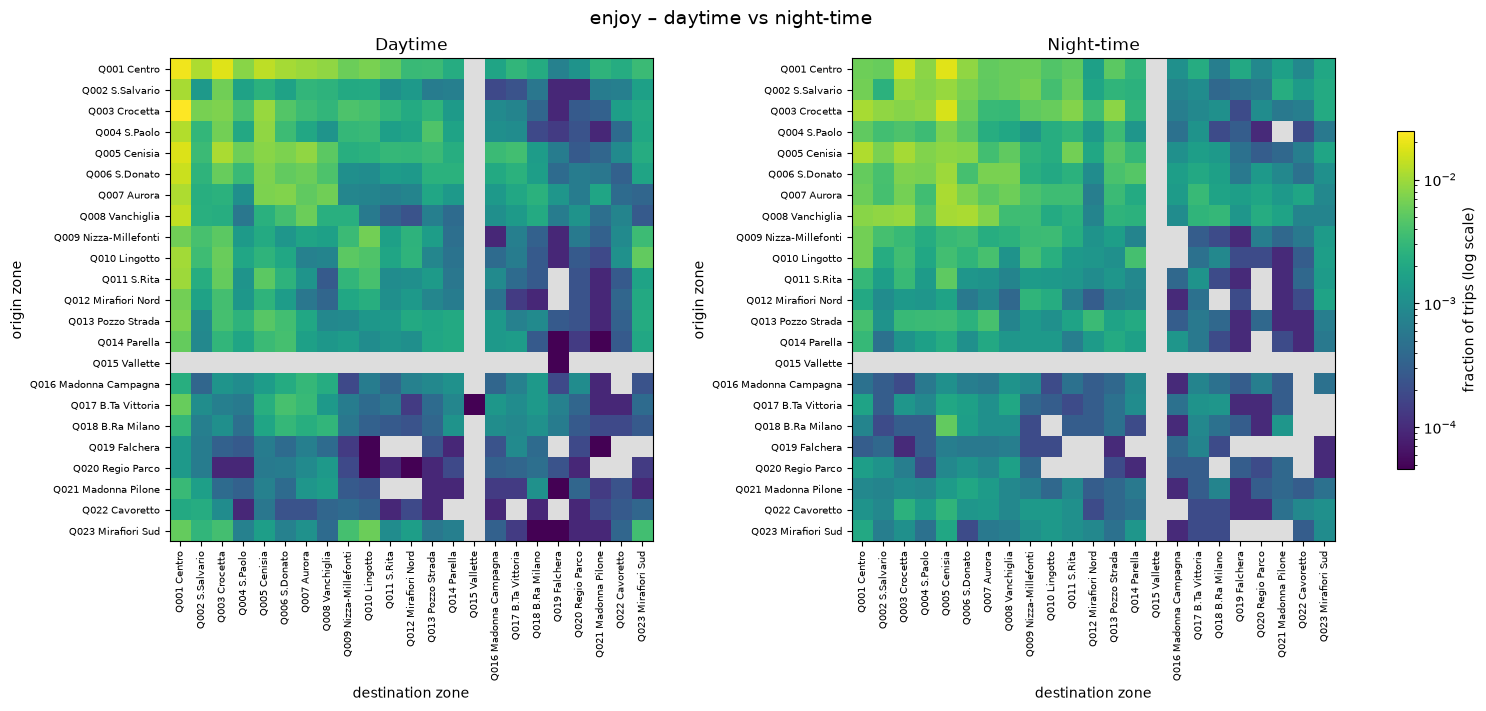

In [52]:
for vendor, P in od_periods.items():
    plot_heatmaps({'Weekdays': P['Weekdays']['probability'], 'Weekends': P['Weekends']['probability']},
                  f'{vendor} – weekdays vs weekends', f'task1a_{vendor}_week')
    plot_heatmaps({'Daytime': P['Daytime']['probability'], 'Night-time': P['Night-time']['probability']},
                  f'{vendor} – daytime vs night-time', f'task1a_{vendor}_day')

### Where are the differences?

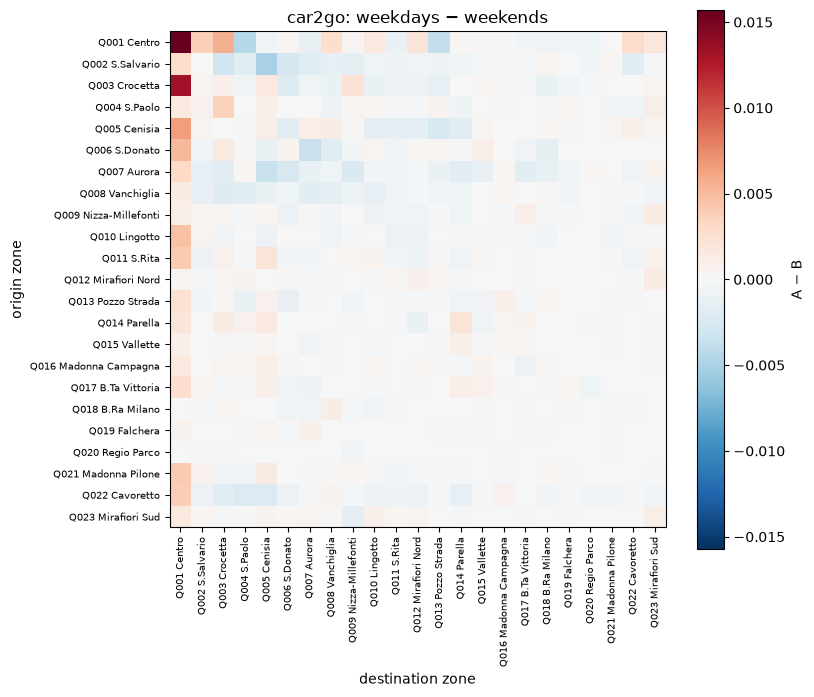

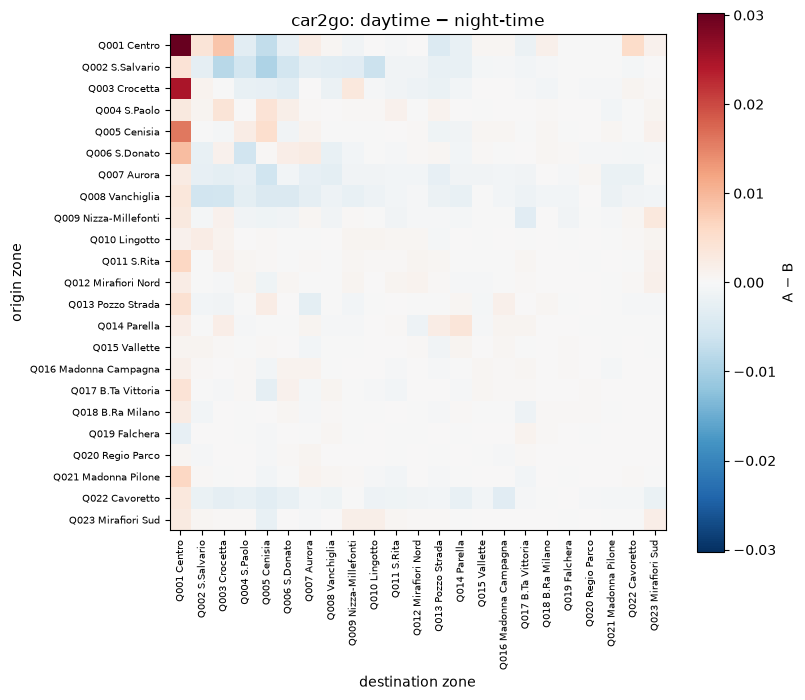

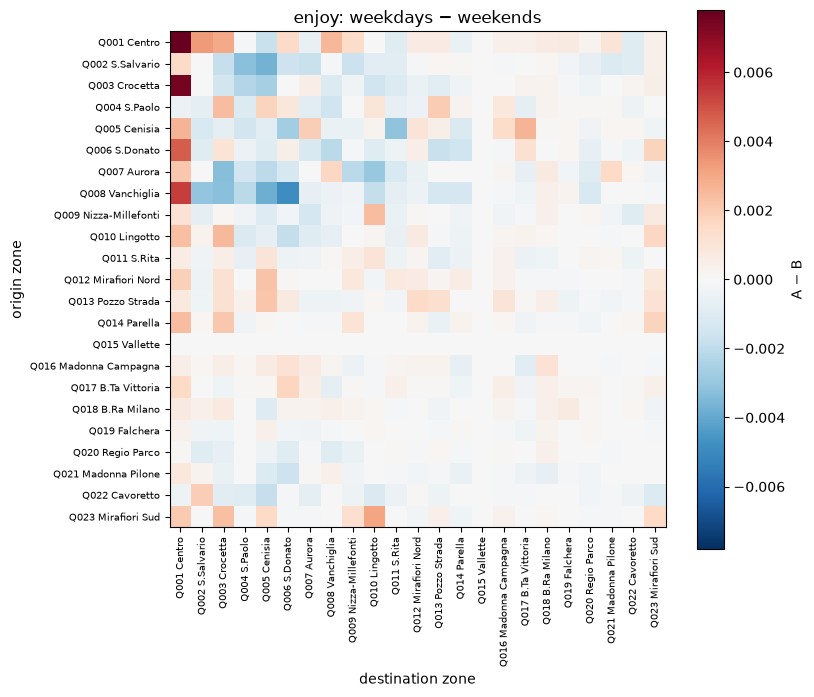

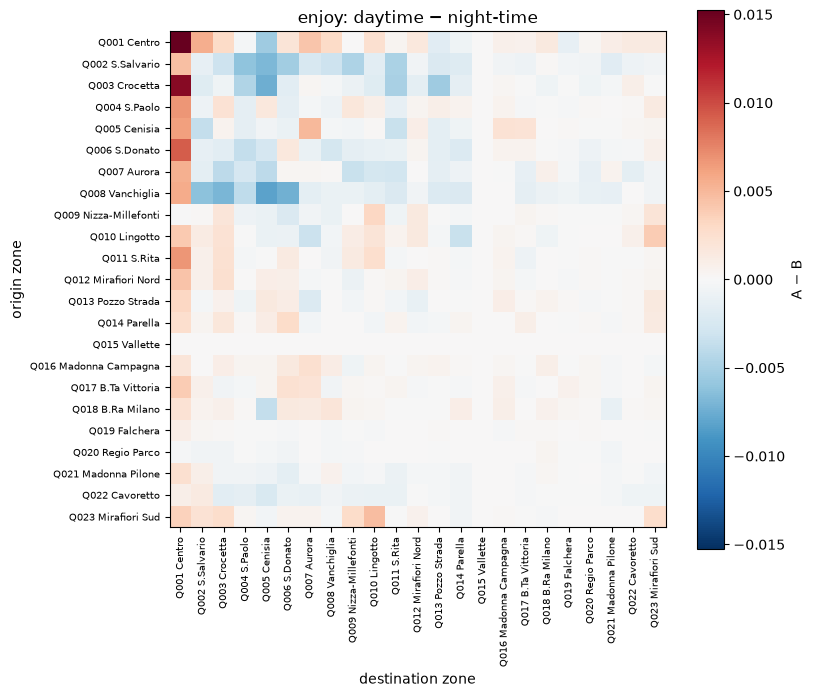

In [53]:
#red means more in period 1, blue means more in perod 2

for vendor, P in od_periods.items():
    plot_difference(P['Weekdays']['probability'], P['Weekends']['probability'],
                    f'{vendor}: weekdays − weekends', f'task1a_{vendor}_diff_week')
    plot_difference(P['Daytime']['probability'], P['Night-time']['probability'],
                    f'{vendor}: daytime − night-time', f'task1a_{vendor}_diff_day')

### Trip generation (pO) and attraction (pD) per zone

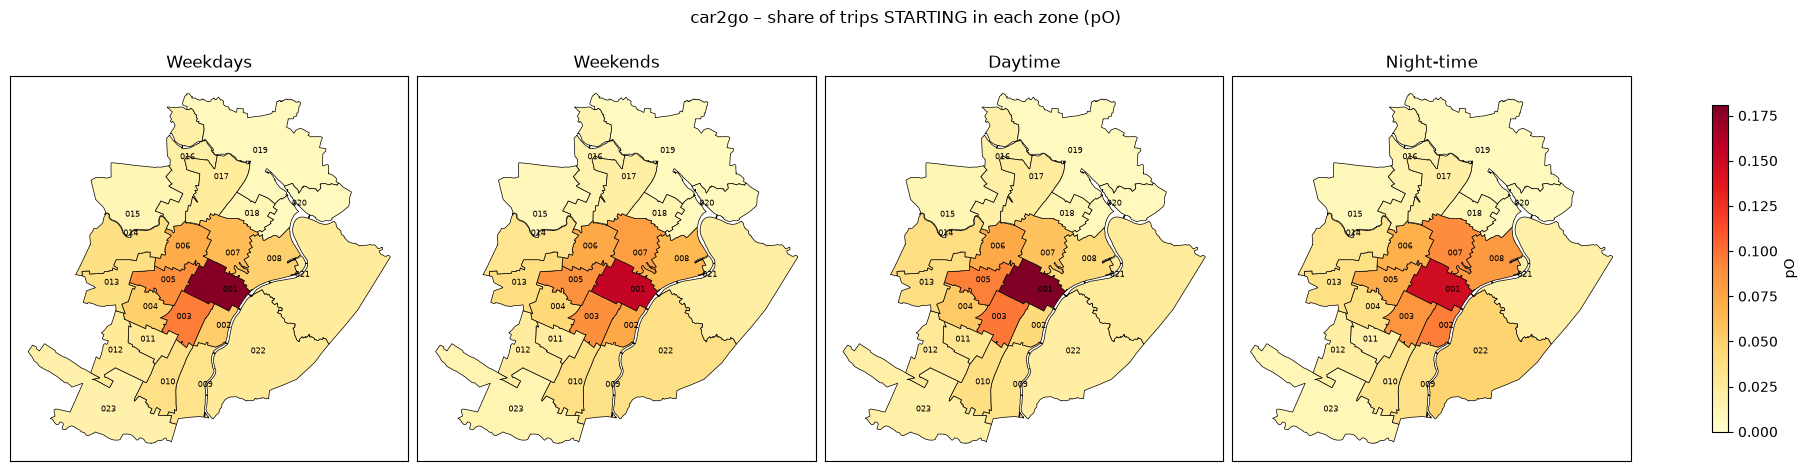

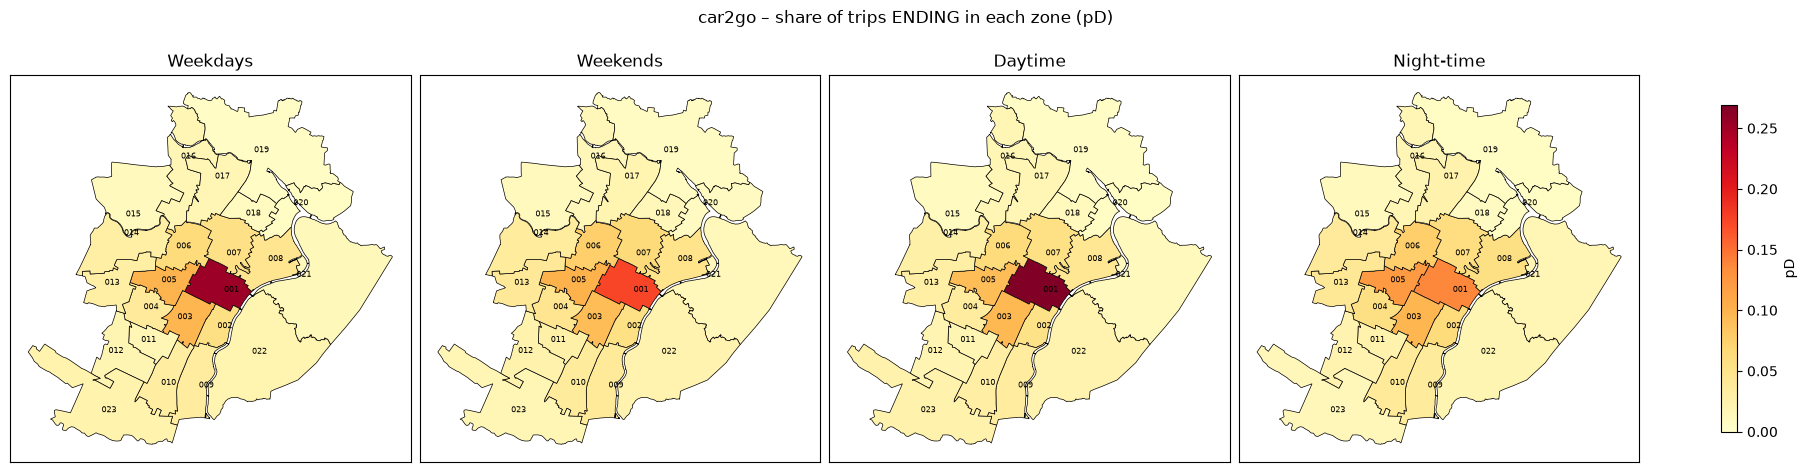

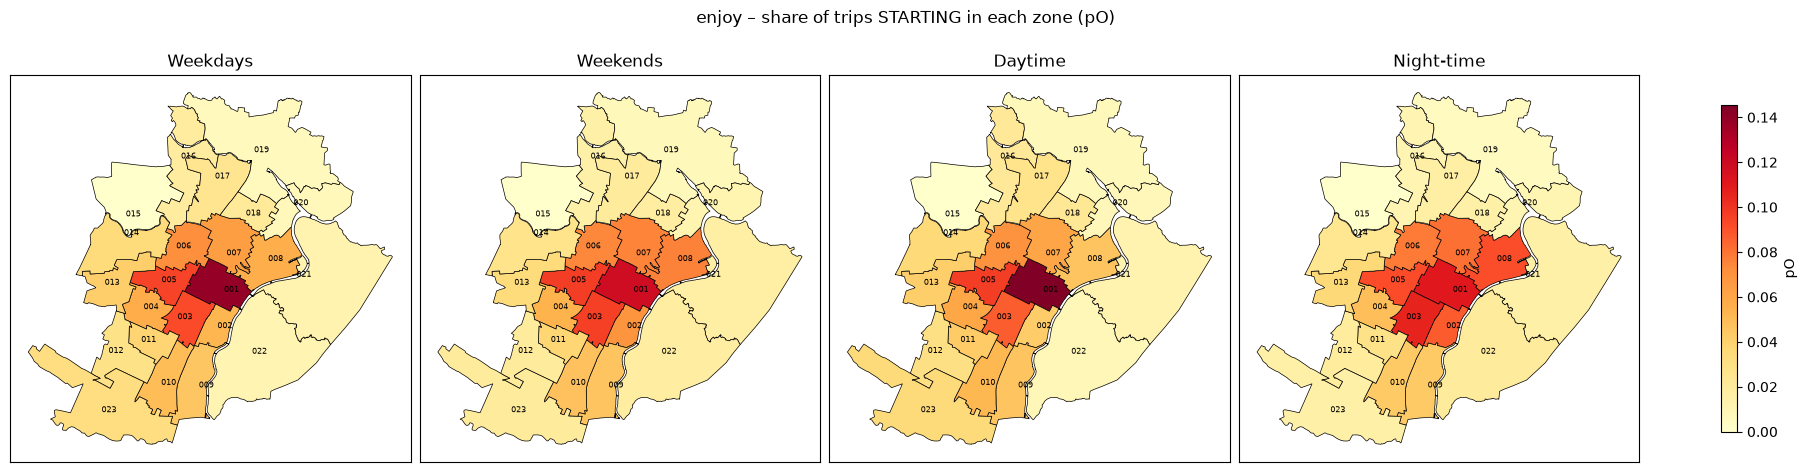

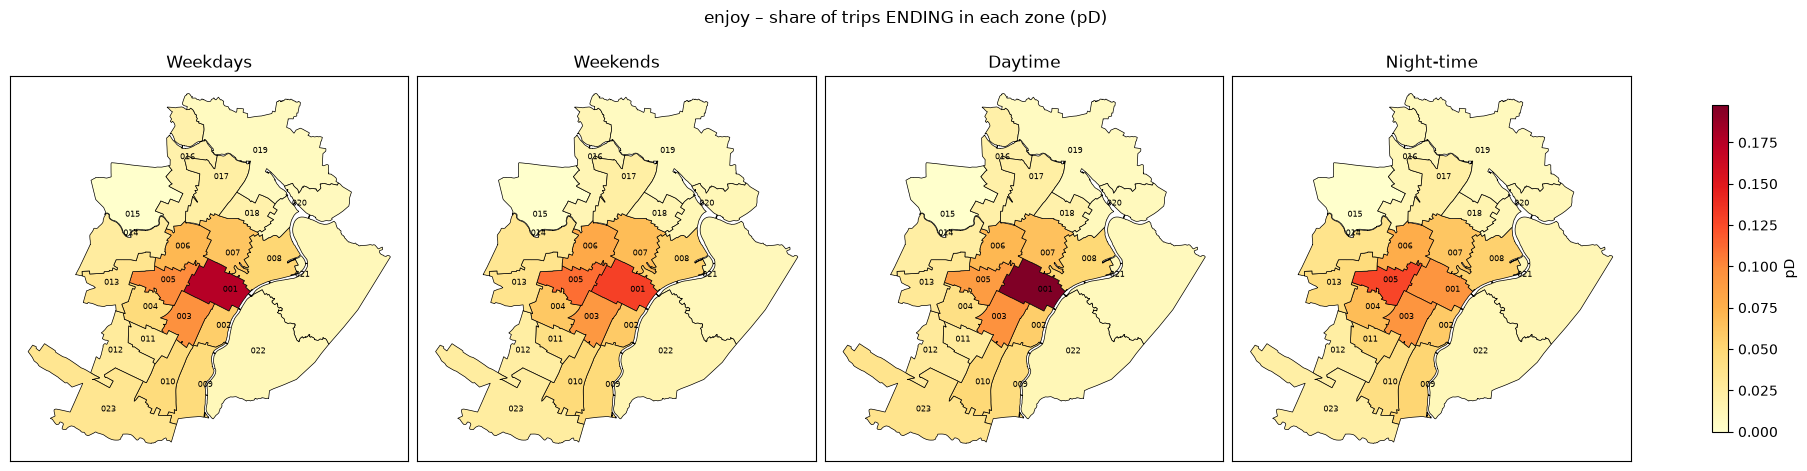

In [54]:
#geographical view of departures and arrival 
for vendor, P in od_periods.items():
    plot_zone_maps({name: r['probability'].sum(axis=1) for name, r in P.items()}, zones,
                   f'{vendor} – share of trips STARTING in each zone (pO)', f'task1a_{vendor}_pO', 'pO')
    plot_zone_maps({name: r['probability'].sum(axis=0) for name, r in P.items()}, zones,
                   f'{vendor} – share of trips ENDING in each zone (pD)', f'task1a_{vendor}_pD', 'pD')

### Task 1b: compare different dates


In [55]:
for vendor, df in trips.items():
    wd = select_period(df, days='weekdays', holidays=HOLIDAYS)
    print(vendor, '- weekday trips per week (rows) and day (0 = Monday)')
    display(pd.crosstab(wd.week, wd.dow))

car2go - weekday trips per week (rows) and day (0 = Monday)


dow,0,1,2,3,4
week,,,,,
0,0,0,0,0,752
1,0,804,497,420,740
2,730,681,807,394,714
3,483,584,603,657,700
4,161,208,489,741,769
5,737,560,806,394,690
6,720,785,536,719,495
7,763,718,422,657,844
8,772,593,405,663,689


enjoy - weekday trips per week (rows) and day (0 = Monday)


dow,0,1,2,3,4
week,,,,,
0,0,0,0,0,657
1,0,271,458,764,371
2,611,651,566,681,568
3,597,605,592,620,144
4,687,700,652,628,624
5,596,660,88,694,567
6,527,592,589,644,553
7,580,679,632,700,145
8,599,675,554,617,601


In [56]:
WEEK_A, WEEK_B = 1, 2

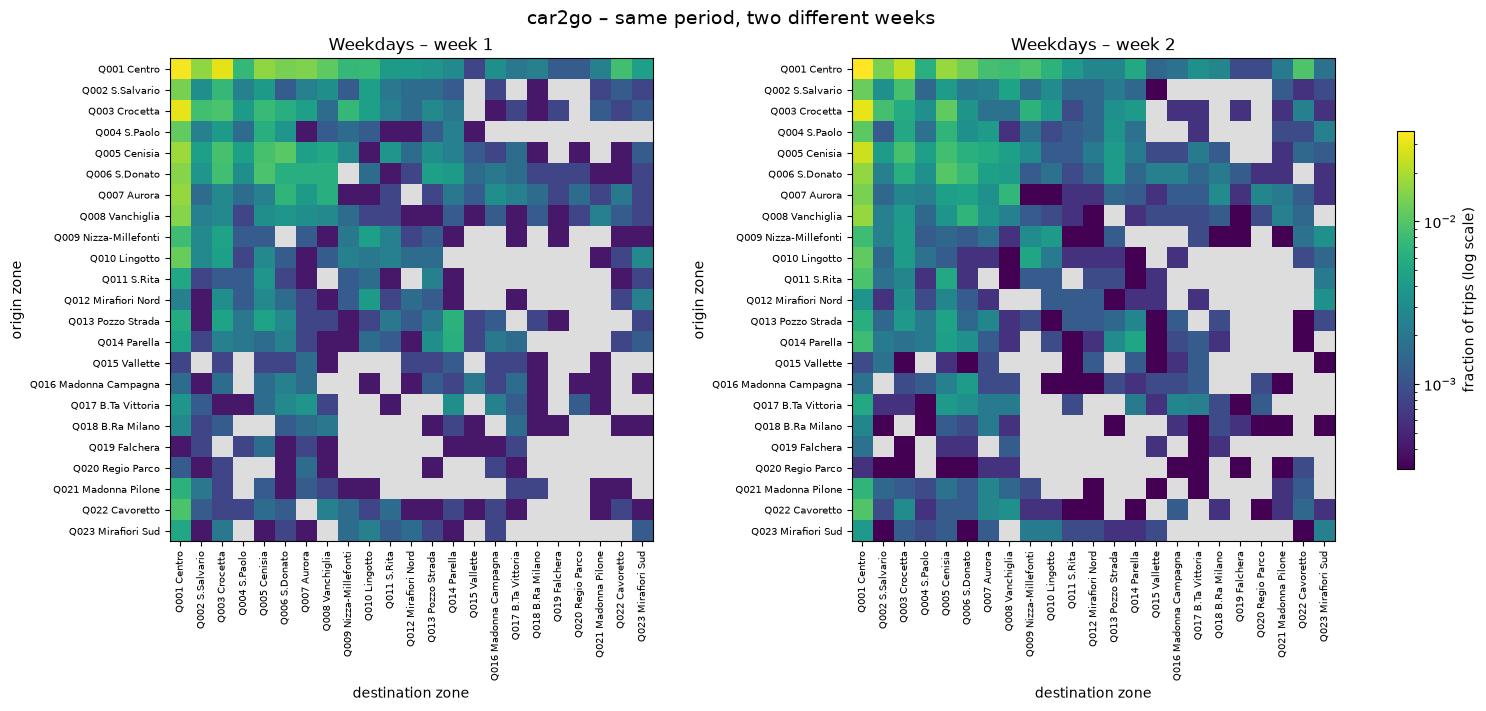

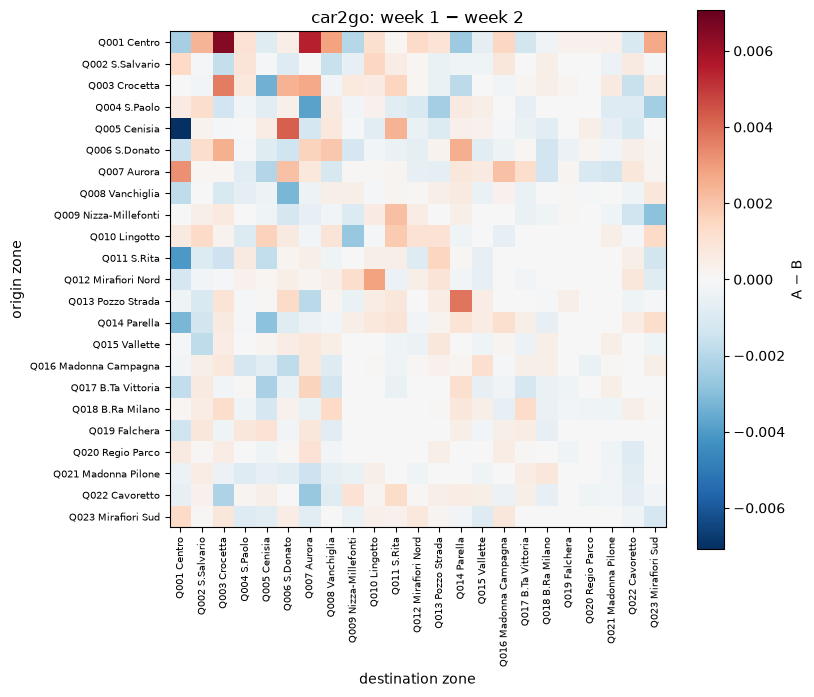

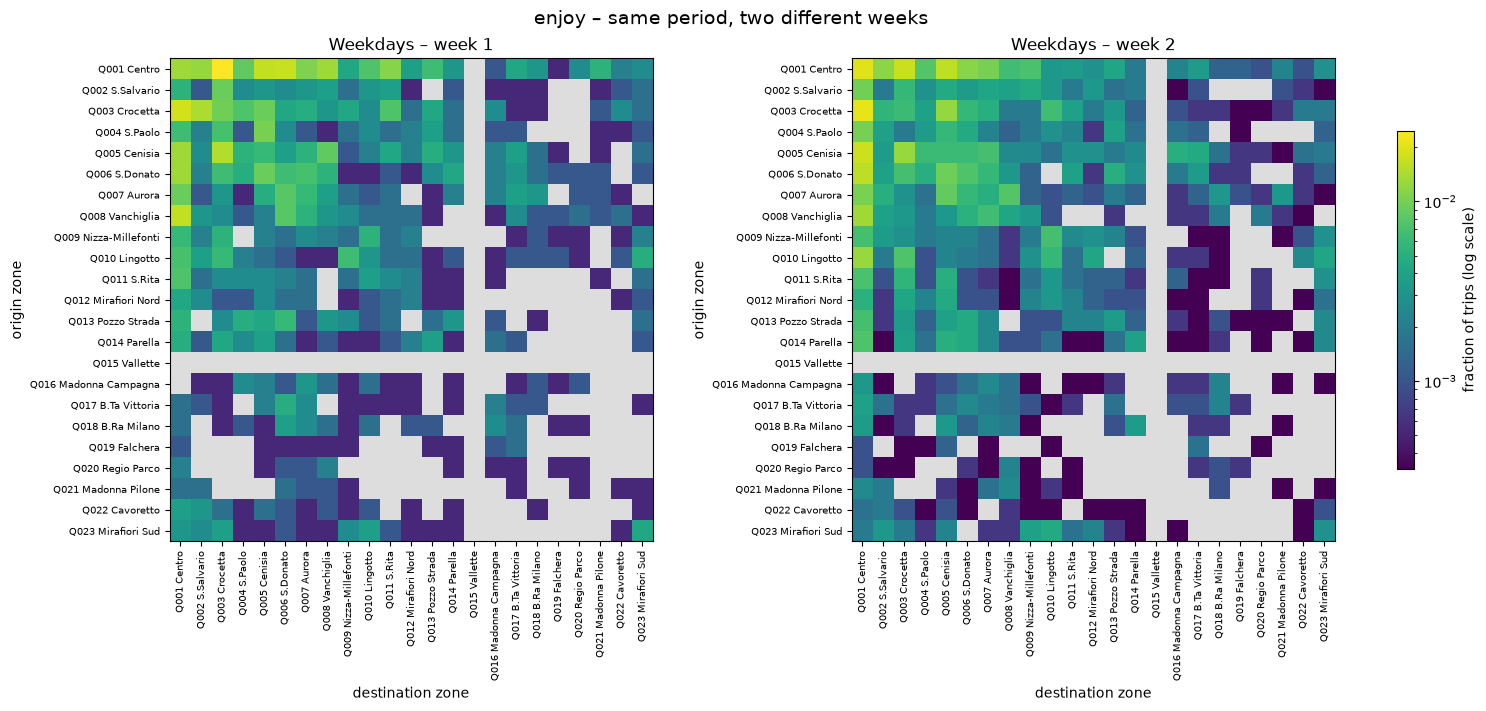

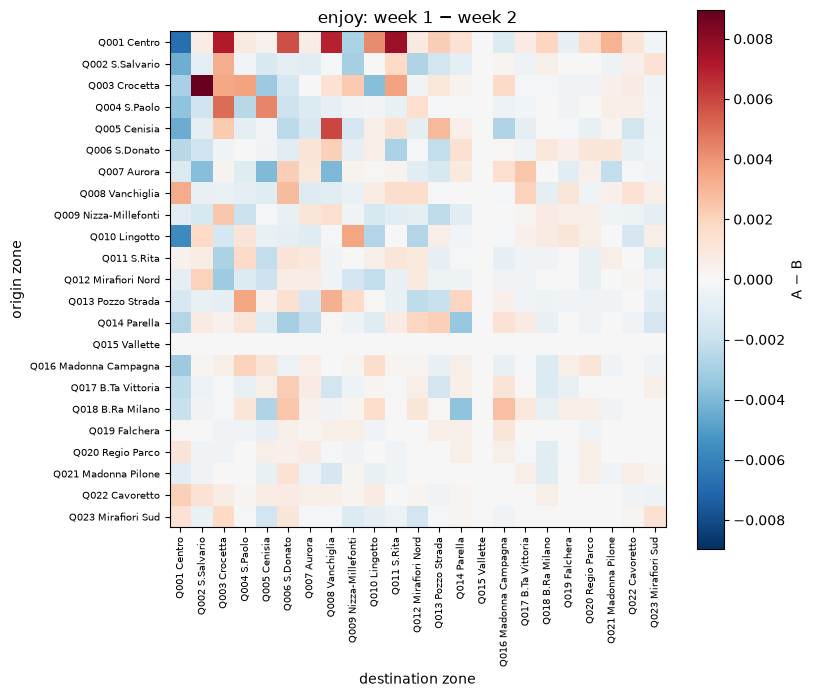

In [57]:
od_weeks = {}
for vendor, df in trips.items():
    A = od_matrix(select_period(df, days='weekdays', weeks=[WEEK_A], holidays=HOLIDAYS), ZONES)
    B = od_matrix(select_period(df, days='weekdays', weeks=[WEEK_B], holidays=HOLIDAYS), ZONES)
    od_weeks[vendor] = (A, B)
    plot_heatmaps({f'Weekdays – week {WEEK_A}': A, f'Weekdays – week {WEEK_B}': B},
                  f'{vendor} – same period, two different weeks', f'task1b_{vendor}_weeks')
    plot_difference(A, B, f'{vendor}: week {WEEK_A} − week {WEEK_B}', f'task1b_{vendor}_diff')

In [58]:
rows = []
for vendor, df in trips.items():
    wd = select_period(df, days='weekdays', holidays=HOLIDAYS)
    weeks = [w for w, g in wd.groupby('week') if w >= 1 and g.dow.nunique() >= 4]   # full weeks (4 days if a holiday)
    mats = {w: od_matrix(wd[wd.week == w], ZONES) for w in weeks}
    for w1, w2 in zip(weeks[:-1], weeks[1:]):
        rows.append({'vendor': vendor, 'pair': f'week {w1} vs {w2}', 'TVD (%)': tvd(mats[w1], mats[w2])})
week_tvd = pd.DataFrame(rows).round(1)
week_tvd.pivot(index='pair', columns='vendor', values='TVD (%)')

vendor,car2go,enjoy
pair,,
week 1 vs 2,17.5,24.6
week 2 vs 3,18.1,18.2
week 3 vs 4,18.3,19.2
week 4 vs 5,19.4,20.0
week 5 vs 6,17.6,20.5
week 6 vs 7,16.7,20.4
week 7 vs 8,19.1,20.6


In [61]:
comparison = {}
for vendor, df in trips.items():
    week_a = select_period(df, weeks=[WEEK_A])
    comparison[vendor] = {
        f'Weekdays: week {WEEK_A} vs week {WEEK_B}':  tvd(*od_weeks[vendor]),
        'Weekdays: consecutive weeks (mean)':      week_tvd[week_tvd.vendor == vendor]['TVD (%)'].mean(),
        f'Weekdays vs weekend, same week {WEEK_A}': tvd(od_matrix(select_period(week_a, days='weekdays', holidays=HOLIDAYS), ZONES),
                                                     od_matrix(select_period(week_a, days='weekend'), ZONES)),
        'Weekdays vs Weekends, all data (1a)':      tvd(od_matrix(select_period(df, days='weekdays', holidays=HOLIDAYS), ZONES),
                                                     od_matrix(select_period(df, days='weekend'), ZONES)),
        'Daytime vs Night-time, all data (1a)':     tvd(od_matrix(select_period(df, hours=DAY_HOURS), ZONES),
                                                     od_matrix(select_period(df, hours=DAY_HOURS[::-1]), ZONES)),
    }
comparison = pd.DataFrame(comparison).round(1)
comparison.to_csv('out/task1b_comparison.csv')
comparison

,car2go,enjoy
Weekdays: week 1 vs week 2,17.5,24.6
Weekdays: consecutive weeks (mean),18.1,20.5
"Weekdays vs weekend, same week 1",26.3,30.6
"Weekdays vs Weekends, all data (1a)",17.4,16.3
"Daytime vs Night-time, all data (1a)",28.1,27.5


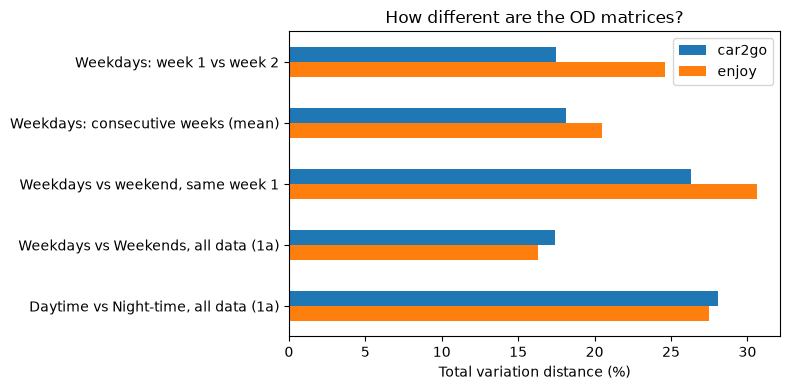

In [62]:
comparison.plot.barh(figsize=(8, 4))
plt.xlabel('Total variation distance (%)'); plt.title('How different are the OD matrices?')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.savefig('out/task1b_comparison.png', dpi=200); plt.show()

### Task 1c OD matrices for Car2Go and Enjoy

I want to use only the dates in both. This way its fully compared 

In [63]:
common_dates = sorted(set(trips['car2go'].date) & set(trips['enjoy'].date))
print(f'{len(common_dates)} dates with data for both platforms: {common_dates[0]} -> {common_dates[-1]}')
same = {v: df[df.date.isin(common_dates)] for v, df in trips.items()}

59 dates with data for both platforms: 2017-09-01 -> 2017-10-31


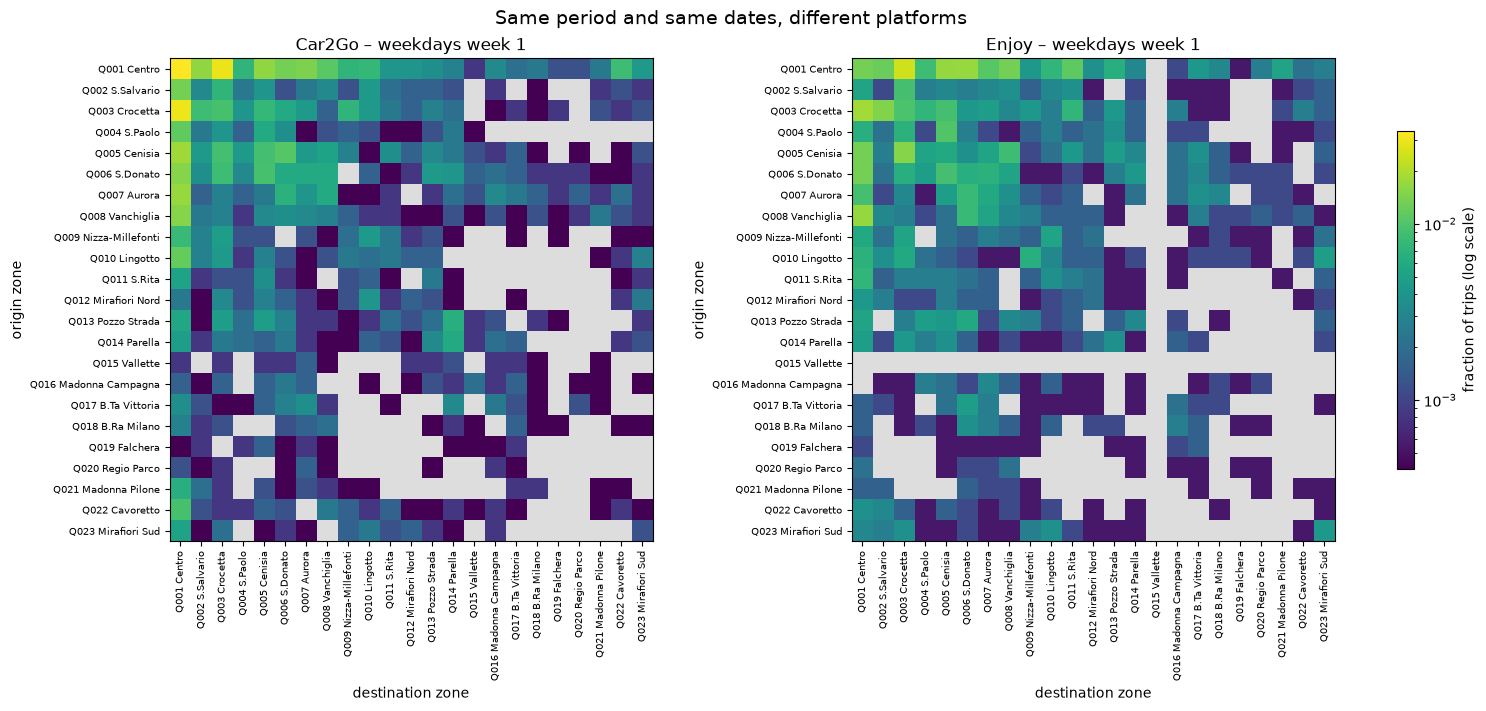

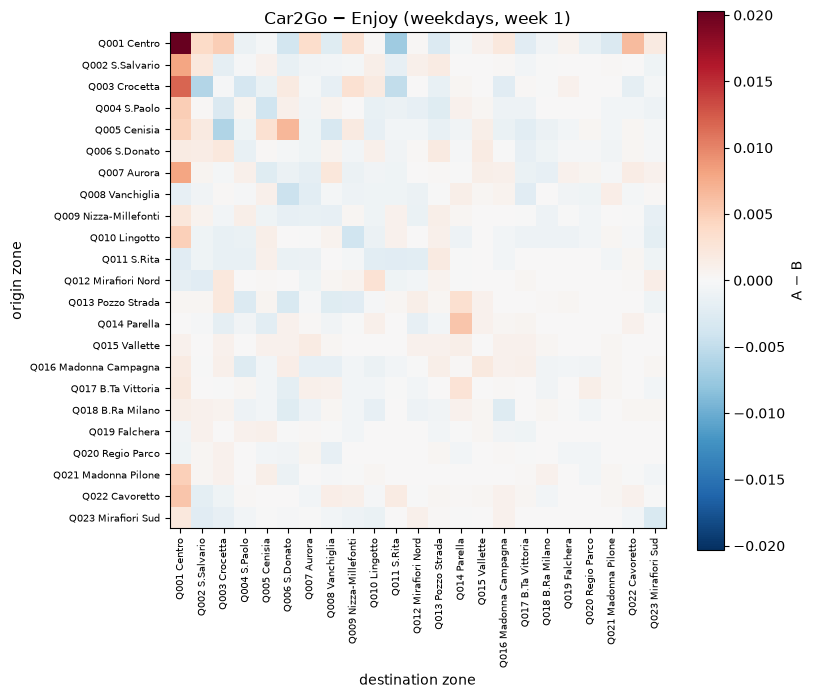

In [64]:
od_vendor = {v: od_matrix(select_period(df, days='weekdays', weeks=[WEEK_A], holidays=HOLIDAYS), ZONES)
             for v, df in same.items()}
plot_heatmaps({f'Car2Go – weekdays week {WEEK_A}': od_vendor['car2go'],
               f'Enjoy – weekdays week {WEEK_A}': od_vendor['enjoy']},
              'Same period and same dates, different platforms', 'task1c_heatmaps')
plot_difference(od_vendor['car2go'], od_vendor['enjoy'], f'Car2Go − Enjoy (weekdays, week {WEEK_A})', 'task1c_diff')

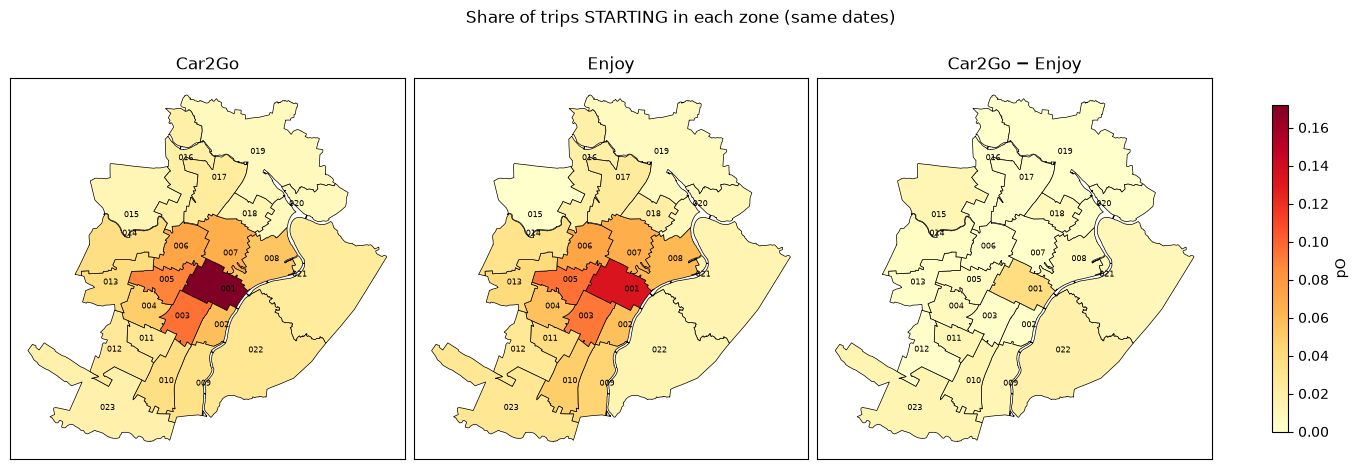

In [65]:
pO = {v: od_matrix(df, ZONES).sum(axis=1) for v, df in same.items()}
pD = {v: od_matrix(df, ZONES).sum(axis=0) for v, df in same.items()}
plot_zone_maps({'Car2Go': pO['car2go'], 'Enjoy': pO['enjoy'], 'Car2Go − Enjoy': (pO['car2go'] - pO['enjoy']).abs()},
               zones, 'Share of trips STARTING in each zone (same dates)', 'task1c_pO', 'pO')

In [70]:
coverage = pd.DataFrame({
    'zone': [f'{z} {ZONE_NAMES[z]}' for z in ZONES],
    'Car2Go pO (%)': pO['car2go'].values * 100, 'Enjoy pO (%)': pO['enjoy'].values * 100,
    'Car2Go pD (%)': pD['car2go'].values * 100, 'Enjoy pD (%)': pD['enjoy'].values * 100,
})
coverage['diff pO (p.p.)'] = coverage['Car2Go pO (%)'] - coverage['Enjoy pO (%)']
coverage.round(2).sort_values('diff pO (p.p.)', key=abs, ascending=False) 


,zone,Car2Go pO (%),Enjoy pO (%),Car2Go pD (%),Enjoy pD (%),diff pO (p.p.)
0,Q001 Centro,17.18,13.41,23.29,16.42,3.77
21,Q022 Cavoretto,2.88,1.27,2.15,1.13,1.62
9,Q010 Lingotto,3.65,4.90,3.38,4.66,-1.25
22,Q023 Mirafiori Sud,1.67,2.89,2.18,3.14,-1.22
8,Q009 Nizza-Millefonti,3.42,4.55,3.58,4.64,-1.13
10,Q011 S.Rita,2.69,3.82,2.08,3.40,-1.13
14,Q015 Vallette,1.10,0.00,1.06,0.00,1.09
20,Q021 Madonna Pilone,2.33,1.33,1.36,1.01,0.99
7,Q008 Vanchiglia,5.34,6.10,4.74,5.11,-0.76
17,Q018 B.Ra Milano,1.28,2.04,1.15,1.80,-0.76


I sorted on absolute value of the diff, I will check if there are better ways to visualize it

In [67]:
top_changes(od_vendor['car2go'], od_vendor['enjoy'], 'Car2Go', 'Enjoy')

,origin,destination,Car2Go (%),Enjoy (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,3.37,1.34,2.03
1,Q003 Crocetta,Q001 Centro,3.01,1.82,1.18
2,Q002 S.Salvario,Q001 Centro,1.34,0.54,0.80
3,Q007 Aurora,Q001 Centro,1.71,0.91,0.79
4,Q001 Centro,Q011 S.Rita,0.41,1.13,-0.72
5,Q005 Cenisia,Q006 S.Donato,1.06,0.38,0.68
6,Q001 Centro,Q022 Cavoretto,0.85,0.21,0.64
7,Q005 Cenisia,Q003 Crocetta,0.89,1.50,-0.61
8,Q003 Crocetta,Q002 S.Salvario,0.85,1.45,-0.60
9,Q022 Cavoretto,Q001 Centro,0.93,0.38,0.56
